# Window Hyperparameter tuning

Deciding between Expanding Window (1) and Rolling Window (2)

Expanding Window:
* minimum initial days: 20 days
* weighting: no recency weighting, with recency weighting (0.03/0.05/0.10)

Note: fix minimum initial days to be fixed for more meaningful comparison, as I move towards future classification, it will be train time_step 1-35, predict time_step 36. Thus, tuning the minimum initial days has no use

Rolling window:
* fixed window days: 5 days, 10 days, 15 days, 20 days

I am using LightGBM as the benchmark to decide which tactic would be better

--------------------
**Note**: As I am graded based on roc-auc score, all items in part 2 is to be tuned based on roc-auc

Experiment order:
1. Select temporal window using train_raw features with time-split graph features, excluding time_step (* from retrospective labelling, lightGBM performed best with no transformation to the raw features)
  * as time_step is not relevant (as this is forward facing, eg. train on time 1-20, classify 21), i felt that time_step is irrelevant and should be removed to prevent overfitting
2. compare the best configuration with and without `time_step`, to see if `time_step` is worth including as a feature
3. Investigate poor performance of time_step 23, 26 & 33, which saw a drop in roc-auc across all temporal window configs

-------------------
Final Results
1. best temporal window is an `Expanding window` with a `decay_rate` of `0.03` (note: testing separately with initial window of 30 yielded the same results)
2. adding `time_step` yielded sightly worse roc-auc results. Moreover, as the objective is to predict future time periods beyong the training range, `time_step` should be excluded 
3. poor performance at `time_step` 23 & 33 can be attributed to class imbalance. However, `time_step` 26 is noted to have a similar portion of illicit classes compared to other time_steps. Moreover, removing top drifting features (for both time steps, feature 100, 101, 103, 136, 137, 139 are the top dirfting features) for both time_steps did slightly worse roc_auc.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ks_2samp
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.utils.class_weight import compute_sample_weight
from lightgbm import LGBMClassifier


In [2]:
### Load data

#note: these are all the original files

train_raw = pd.read_csv("train.csv", header = 0)
test_raw = pd.read_csv("test.csv", header = 0)
edges_raw = pd.read_csv("txs_edgelist.csv", header = 0)

In [3]:
labelled_train = train_raw[train_raw["label"].notna()].copy()
labelled_train["label"] = labelled_train["label"].astype(int)

print("Train shape:", train_raw.shape)
print("Test shape:", test_raw.shape)
print("Edges shape:", edges_raw.shape)
print("Labelled rows:", len(labelled_train))
print(labelled_train["label"].value_counts())

Train shape: (141772, 168)
Test shape: (15329, 168)
Edges shape: (234355, 2)
Labelled rows: 31235
label
0    27591
1     3644
Name: count, dtype: int64


### Temporal graph features

* calculate the graph features using only edges whose two endpoints are knwon by the relevant cutoff time
* prevent future transaction edges from being used to construct training and validatoin features

note: transaction edge list is provided without test labels, so for the final competition model, can just add it in

In [4]:
# Use the train/test time mapping to decide whether an edge endpoint is
# temporally available at a given cutoff.
node_times = pd.concat(
    [
        train_raw[["txId", "time_step"]],
        test_raw[["txId", "time_step"]],
    ],
    ignore_index=True,
).drop_duplicates("txId").set_index("txId")["time_step"]

edges = edges_raw[["txId1", "txId2"]].copy()
edges["time_1"] = edges["txId1"].map(node_times)
edges["time_2"] = edges["txId2"].map(node_times)

print("Edges with unknown endpoint time:", edges[["time_1", "time_2"]].isna().any(axis=1).sum())

Edges with unknown endpoint time: 58437


In [5]:
def temporal_node_features(cutoff_step):
    """Compute structural node features using edges available by cutoff_step."""
    usable_edges = edges[
        edges["time_1"].notna()
        & edges["time_2"].notna()
        & (edges["time_1"] <= cutoff_step)
        & (edges["time_2"] <= cutoff_step)
    ]

    in_degree = usable_edges.groupby("txId2").size().rename("in_degree")
    out_degree = usable_edges.groupby("txId1").size().rename("out_degree")

    features = pd.concat([in_degree, out_degree], axis=1).fillna(0)
    features["total_degree"] = (
        features["in_degree"] + features["out_degree"]
    )
    features["degree_ratio"] = (
        features["out_degree"]
        / features["in_degree"].replace(0, np.nan)
    )
    features["degree_ratio"] = (
        features["degree_ratio"]
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
    )

    return features.reset_index().rename(columns={"index": "txId"})


graph_feature_cols = [
    "in_degree",
    "out_degree",
    "total_degree",
    "degree_ratio",
]

## Feature set
* exclude `time_step` from experiment step 1

In [6]:
base_feature_cols = [
    c for c in train_raw.columns
    if c not in ["txId", "label", "time_step"]
]

print("Original feature count:", len(base_feature_cols))

Original feature count: 165


In [7]:
def add_temporal_graph_features(frame, cutoff_step):
    graph_features = temporal_node_features(cutoff_step)
    result = frame.merge(graph_features, on="txId", how="left")
    result[graph_feature_cols] = result[graph_feature_cols].fillna(0)
    return result

# Show an example of the strict graph feature construction.
example_graph = add_temporal_graph_features(
    labelled_train.head(10),
    cutoff_step=labelled_train["time_step"].min(),
)
display(example_graph[["txId", "time_step"] + graph_feature_cols].head())

,txId,time_step,in_degree,out_degree,total_degree,degree_ratio
0,232438397,1,160.0,1.0,161.0,0.006250
1,232029206,1,59.0,1.0,60.0,0.016949
2,232344069,1,0.0,2.0,2.0,0.000000
3,27553029,1,1.0,1.0,2.0,1.000000
4,3881097,1,1.0,1.0,2.0,1.000000


In [8]:
def create_lightgbm():
    return LGBMClassifier(
        objective="binary",
        random_state=100,
        n_jobs=-1,
        verbosity = -1
    )

def calculate_recency_weights(
    time_steps,
    reference_time_step,
    decay_rate,
):
    """
    Exponential recency weighting.

    More recent observations receive larger weights.
    """

    age = reference_time_step - time_steps

    weights = np.exp(
        -decay_rate * age
    )

    return weights

In [9]:
def evaluate_temporal_configuration(
    data,
    feature_cols,
    strategy,
    window_size,
    recency_decay=0.0,
    min_validation_step=21,
    use_time_step=False,
    use_graph_features=True,
    verbose=False,
):
    """Forward validation with strict temporal graph features."""
    data = data.copy()
    available_steps = sorted(data["time_step"].dropna().unique())
    fold_results = []

    for validation_step in available_steps:
        if validation_step < min_validation_step:
            continue

        train_end_step = validation_step - 1

        if strategy == "expanding":
            train_start_step = available_steps[0]
            if len([s for s in available_steps if s <= train_end_step]) < window_size:
                continue
        elif strategy == "rolling":
            train_start_step = train_end_step - window_size + 1
        else:
            raise ValueError("strategy must be 'expanding' or 'rolling'")

        train_fold = data[
            (data["time_step"] >= train_start_step)
            & (data["time_step"] <= train_end_step)
            & data["label"].notna()
        ].copy()
        validation_fold = data[
            (data["time_step"] == validation_step)
            & data["label"].notna()
        ].copy()

        if train_fold.empty or validation_fold.empty:
            continue

        y_train = train_fold["label"].astype(int)
        y_valid = validation_fold["label"].astype(int)
        if y_train.nunique() < 2 or y_valid.nunique() < 2:
            continue

        if use_graph_features:
            train_fold = add_temporal_graph_features(train_fold, train_end_step)
            validation_fold = add_temporal_graph_features(validation_fold, validation_step)

        fold_features = list(feature_cols)
        if use_graph_features:
            fold_features = fold_features + graph_feature_cols
        if use_time_step:
            fold_features = fold_features + ["time_step"]

        X_train = train_fold[fold_features]
        X_valid = validation_fold[fold_features]

        class_weights = compute_sample_weight("balanced", y_train)
        recency_weights = calculate_recency_weights(
            train_fold["time_step"].to_numpy(),
            train_end_step,
            recency_decay,
        )
        sample_weights = class_weights * recency_weights
        sample_weights = sample_weights / sample_weights.mean()

        model = create_lightgbm()
        model.fit(X_train, y_train, sample_weight=sample_weights)
        valid_prob = model.predict_proba(X_valid)[:, 1]

        if verbose:
            print(f"Train: {train_start_step}–{train_end_step} | Validate: {validation_step}")

        fold_results.append({
            "strategy": strategy,
            "window_size": window_size,
            "recency_decay": recency_decay,
            "validation_step": validation_step,
            "train_start_step": train_start_step,
            "train_end_step": train_end_step,
            "n_train": len(train_fold),
            "n_validation": len(validation_fold),
            "positive_validation": int(y_valid.sum()),
            "pr_auc": average_precision_score(y_valid, valid_prob),
            "roc_auc": roc_auc_score(y_valid, valid_prob),
            "use_time_step": use_time_step,
        })

    return pd.DataFrame(fold_results)

# 1. Test performance on variations of the window

In [10]:
configurations = []

for decay in [0.00, 0.03, 0.05, 0.10, 0.20]:
    configurations.append({
        "strategy": "expanding",
        "window_size": 20,
        "recency_decay": decay,
    })

for window_size in [10, 15, 20]:
    configurations.append({
        "strategy": "rolling",
        "window_size": window_size,
        "recency_decay": 0.00,
    })

configurations_df = pd.DataFrame(configurations)
display(configurations_df)
print("Number of configurations:", len(configurations_df))

,strategy,window_size,recency_decay
0,expanding,20,0.00
1,expanding,20,0.03
2,expanding,20,0.05
3,expanding,20,0.10
4,expanding,20,0.20
5,rolling,10,0.00
6,rolling,15,0.00
7,rolling,20,0.00


Number of configurations: 8


In [11]:
window_fold_results = []

for config in configurations:
    print(config)
    result = evaluate_temporal_configuration(
        data=labelled_train,
        feature_cols=base_feature_cols,
        strategy=config["strategy"],
        window_size=config["window_size"],
        recency_decay=config["recency_decay"],
        min_validation_step=21,
        use_time_step=False,
        use_graph_features=True,
    )
    window_fold_results.append(result)

window_fold_results = pd.concat(window_fold_results, ignore_index=True)

{'strategy': 'expanding', 'window_size': 20, 'recency_decay': 0.0}
{'strategy': 'expanding', 'window_size': 20, 'recency_decay': 0.03}
{'strategy': 'expanding', 'window_size': 20, 'recency_decay': 0.05}
{'strategy': 'expanding', 'window_size': 20, 'recency_decay': 0.1}
{'strategy': 'expanding', 'window_size': 20, 'recency_decay': 0.2}
{'strategy': 'rolling', 'window_size': 10, 'recency_decay': 0.0}
{'strategy': 'rolling', 'window_size': 15, 'recency_decay': 0.0}
{'strategy': 'rolling', 'window_size': 20, 'recency_decay': 0.0}


In [12]:
window_summary = (
    window_fold_results
    .groupby(["strategy", "window_size", "recency_decay"])
    .agg(
        mean_roc_auc=("roc_auc", "mean"),
        median_roc_auc=("roc_auc", "median"),
        std_roc_auc=("roc_auc", "std"),
        worst_roc_auc=("roc_auc", "min"),
        latest_5_roc_auc=("roc_auc", lambda x: x.tail(5).mean()),

        # Keep PR-AUC as a diagnostic
        mean_pr_auc=("pr_auc", "mean"),

        n_folds=("validation_step", "count"),
    )
    .reset_index()
    .sort_values(
        ["mean_roc_auc", "latest_5_roc_auc"],
        ascending=False,
    )
)

display(window_summary)

best_window = window_summary.iloc[0].to_dict()

print("Selected window configuration:")
display(pd.DataFrame([best_window]))

,strategy,window_size,recency_decay,mean_roc_auc,median_roc_auc,std_roc_auc,worst_roc_auc,latest_5_roc_auc,mean_pr_auc,n_folds
1,expanding,20,0.03,0.994933,0.997131,0.009145,0.963346,0.997356,0.973035,15
7,rolling,20,0.00,0.994677,0.996747,0.008537,0.965825,0.996626,0.970193,15
2,expanding,20,0.05,0.994522,0.997295,0.010133,0.959635,0.997147,0.971238,15
0,expanding,20,0.00,0.994411,0.997173,0.010320,0.959119,0.997209,0.971265,15
3,expanding,20,0.10,0.994366,0.998157,0.009148,0.965725,0.995599,0.971084,15
4,expanding,20,0.20,0.994239,0.997891,0.010279,0.958870,0.997329,0.971200,15
6,rolling,15,0.00,0.993486,0.997173,0.013072,0.947656,0.996520,0.970139,15
5,rolling,10,0.00,0.992197,0.997246,0.013991,0.945343,0.994544,0.966219,15


Selected window configuration:


,strategy,window_size,recency_decay,mean_roc_auc,median_roc_auc,std_roc_auc,worst_roc_auc,latest_5_roc_auc,mean_pr_auc,n_folds
0,expanding,20,0.03,0.994933,0.997131,0.009145,0.963346,0.997356,0.973035,15


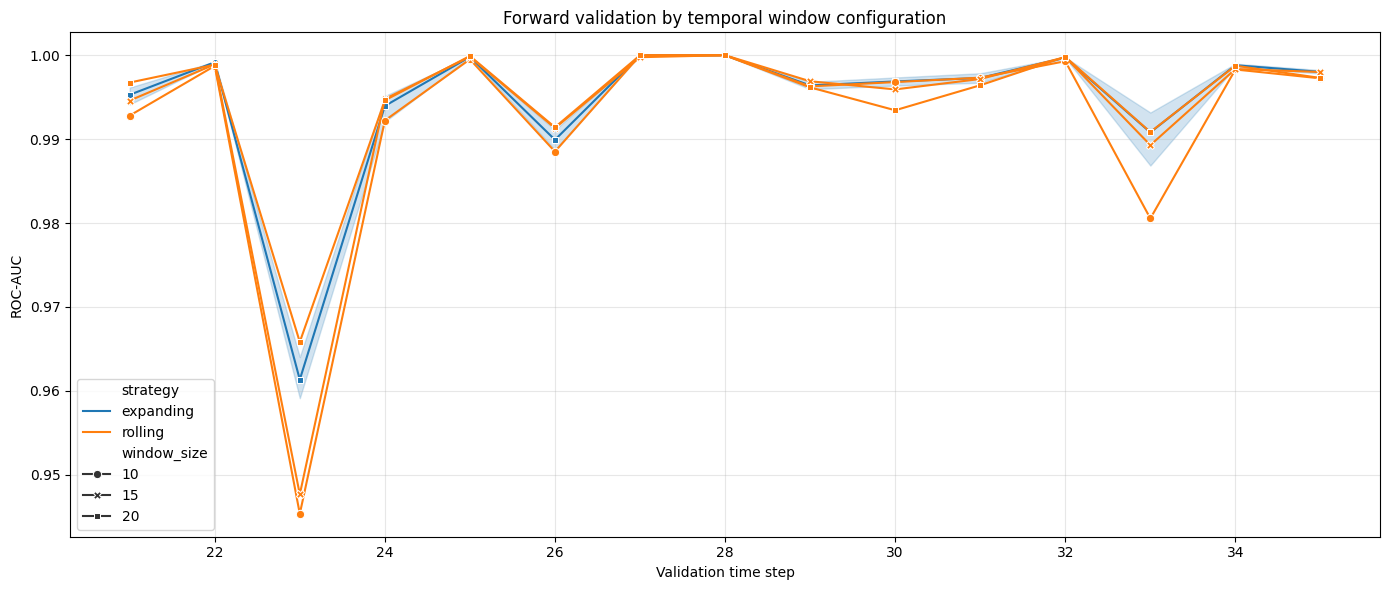

In [13]:
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=window_fold_results,
    x="validation_step",
    y="roc_auc",
    hue="strategy",
    style="window_size",
    markers=True,
    dashes=False,
)
plt.xlabel("Validation time step")
plt.ylabel("ROC-AUC")
plt.title("Forward validation by temporal window configuration")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

To confirm results, rerun the tuning but use 30 days as the initialisation window. check if 0.03 decay rate is the best option

In [14]:
configurations = []

for decay in [0.00, 0.03, 0.05, 0.10]:
    configurations.append({
        "strategy": "expanding",
        "window_size": 30,
        "recency_decay": decay,
    })

configurations_df = pd.DataFrame(configurations)
display(configurations_df)
print("Number of configurations:", len(configurations_df))

,strategy,window_size,recency_decay
0,expanding,30,0.00
1,expanding,30,0.03
2,expanding,30,0.05
3,expanding,30,0.10


Number of configurations: 4


In [15]:
window_fold_results2 = []

for config in configurations:
    print(config)
    result = evaluate_temporal_configuration(
        data=labelled_train,
        feature_cols=base_feature_cols,
        strategy=config["strategy"],
        window_size=config["window_size"],
        recency_decay=config["recency_decay"],
        min_validation_step=31,
        use_time_step=False,
        use_graph_features=True,
    )
    window_fold_results2.append(result)

window_fold_results2 = pd.concat(window_fold_results2, ignore_index=True)

{'strategy': 'expanding', 'window_size': 30, 'recency_decay': 0.0}
{'strategy': 'expanding', 'window_size': 30, 'recency_decay': 0.03}
{'strategy': 'expanding', 'window_size': 30, 'recency_decay': 0.05}
{'strategy': 'expanding', 'window_size': 30, 'recency_decay': 0.1}


In [16]:
window_summary2 = (
    window_fold_results2
    .groupby(["strategy", "window_size", "recency_decay"])
    .agg(
        mean_roc_auc=("roc_auc", "mean"),
        median_roc_auc=("roc_auc", "median"),
        std_roc_auc=("roc_auc", "std"),
        worst_roc_auc=("roc_auc", "min"),
        latest_5_roc_auc=("roc_auc", lambda x: x.tail(5).mean()),

        mean_pr_auc=("pr_auc", "mean"),

        n_folds=("validation_step", "count"),
    )
    .reset_index()
    .sort_values(
        ["mean_roc_auc", "latest_5_roc_auc"],
        ascending=False,
    )
)

display(window_summary2)

best_window2 = window_summary2.iloc[0].to_dict()

print("Selected window configuration:")
display(pd.DataFrame([best_window2]))

,strategy,window_size,recency_decay,mean_roc_auc,median_roc_auc,std_roc_auc,worst_roc_auc,latest_5_roc_auc,mean_pr_auc,n_folds
1,expanding,30,0.03,0.997356,0.998004,0.002369,0.993759,0.997356,0.979021,5
0,expanding,30,0.00,0.997209,0.997720,0.002931,0.992303,0.997209,0.976966,5
2,expanding,30,0.05,0.997147,0.997758,0.002807,0.992511,0.997147,0.976507,5
3,expanding,30,0.10,0.995599,0.998199,0.006989,0.983150,0.995599,0.972007,5


Selected window configuration:


,strategy,window_size,recency_decay,mean_roc_auc,median_roc_auc,std_roc_auc,worst_roc_auc,latest_5_roc_auc,mean_pr_auc,n_folds
0,expanding,30,0.03,0.997356,0.998004,0.002369,0.993759,0.997356,0.979021,5


## 2. Compare with and without `time_step`

Sumary of findings:
* the results with `time_step` performed slightly better than the results without `time_step`
* median and mean pr_auc score improved slightly, and standard deviation reduced slightly
* min pr_auc score remained the same

thus, it would be better to include `time_step` within the features

In [28]:
best_strategy = best_window["strategy"]
best_window_size = int(best_window["window_size"])
best_decay = float(best_window["recency_decay"])

without_time_results = evaluate_temporal_configuration(
    data=labelled_train,
    feature_cols=base_feature_cols,
    strategy=best_strategy,
    window_size=best_window_size,
    recency_decay=best_decay,
    min_validation_step=21,
    use_time_step=False,
    use_graph_features=True,
)

with_time_results = evaluate_temporal_configuration(
    data=labelled_train,
    feature_cols=base_feature_cols,
    strategy=best_strategy,
    window_size=best_window_size,
    recency_decay=best_decay,
    min_validation_step=21,
    use_time_step=True,
    use_graph_features=True,
)

time_comparison = pd.DataFrame({
    "without_time_step": without_time_results.groupby("validation_step")["roc_auc"].first(),
    "with_time_step": with_time_results.groupby("validation_step")["roc_auc"].first(),
}).reset_index()
time_comparison["difference_with_minus_without"] = (
    time_comparison["with_time_step"]
    - time_comparison["without_time_step"]
)
display(time_comparison)

display(pd.DataFrame({
    "without_time_step": without_time_results["roc_auc"].agg(["mean", "median", "std", "min"]),
    "with_time_step": with_time_results["roc_auc"].agg(["mean", "median", "std", "min"]),
}))

,validation_step,without_time_step,with_time_step,difference_with_minus_without
0,21,0.995749,0.995582,-0.000166
1,22,0.999231,0.999278,0.000047
2,23,0.963346,0.963346,0.000000
3,24,0.994059,0.994059,0.000000
4,25,0.999786,0.999822,0.000036
5,26,0.990820,0.988717,-0.002103
6,27,1.000000,1.000000,0.000000
7,28,1.000000,1.000000,0.000000
8,29,0.997094,0.997094,0.000000
9,30,0.997131,0.997131,0.000000


,without_time_step,with_time_step
mean,0.994933,0.994900
median,0.997131,0.997131
std,0.009145,0.009234
min,0.963346,0.963346


## 3. Investigate `time_step` `23`, `26` & `33`

* from Step 1, it is noted that the ROC_AUC score dropped sharply at `time_step` 23, 26 & 33
* Investigations show that the portion of illicit labels are notably fewer in `time_step` 23 & 33, compared to other `time_step` after 20
* Conducting the ks_2samp test between the feature distributions of the prior `time_step` (22 vs 23, 32 vs 33), six features consistently rank the highest: feature 100, 101, 103, 136, 137, 139
* However, re-running the results after removing the features yielded marginal improvement for `time_step 33`, and a slight decrease in roc_auc for `time_step 23`, indicating that the selected features did little to impact the roc_auc score despite a significant shift

Start by checking illicit label distributions over time:
* it is noted that the portion of illicit labels are notably fewer compared to the other time_steps after time_step 20

In [42]:
label_distribution = (
    labelled_train
    .groupby("time_step")["label"]
    .agg(
        n_rows="size",
        n_illicit="sum",
        illicit_rate="mean",
    )
    .reset_index()
)

display(label_distribution)

display(
    label_distribution[
        label_distribution["time_step"].isin([23, 26, 33])
    ]
)

,time_step,n_rows,n_illicit,illicit_rate
0,1,2147,17,0.007918
1,2,1117,18,0.016115
2,3,1279,11,0.008600
3,4,1440,30,0.020833
4,5,1882,8,0.004251
5,6,485,5,0.010309
6,7,1203,102,0.084788
7,8,1165,67,0.057511
8,9,778,248,0.318766
9,10,972,18,0.018519


,time_step,n_rows,n_illicit,illicit_rate
22,23,1187,53,0.044650
25,26,517,96,0.185687
32,33,441,23,0.052154


Now to look for features which are significantly different in time_step 23 and 33
* in both time_step, the features which are strongly different from their previous step (22, 32) are:
* feature 100, 101, 103, 136, 137, 139

In [43]:
# KS drift diagnostics for the two affected transitions.
def compare_adjacent_periods(data, feature_cols, previous_step, current_step):
    previous = data[data["time_step"] == previous_step]
    current = data[data["time_step"] == current_step]
    rows = []
    for feature in feature_cols:
        a = previous[feature].dropna()
        b = current[feature].dropna()
        if len(a) and len(b):
            statistic, p_value = ks_2samp(a, b)
            rows.append({"feature": feature, "ks_statistic": statistic, "p_value": p_value})
    return pd.DataFrame(rows).sort_values("ks_statistic", ascending=False)

drift_22_to_23 = compare_adjacent_periods(labelled_train, base_feature_cols, 22, 23)
drift_25_to_26 = compare_adjacent_periods(labelled_train, base_feature_cols, 25, 26)
drift_32_to_33 = compare_adjacent_periods(labelled_train, base_feature_cols, 32, 33)

print("Drift from time step 22 to 23")
display(drift_22_to_23.head(20))
print("Drift from time step 25 to 26")
display(drift_25_to_26.head(20))
print("Drift from time step 32 to 33")
display(drift_32_to_33.head(20))

Drift from time step 22 to 23


,feature,ks_statistic,p_value
100,feat_101,1.000000,0.000000e+00
102,feat_103,1.000000,0.000000e+00
99,feat_100,0.995788,0.000000e+00
135,feat_136,0.993761,0.000000e+00
138,feat_139,0.902439,0.000000e+00
136,feat_137,0.865003,0.000000e+00
96,feat_97,0.316700,2.041516e-63
94,feat_95,0.305089,8.236574e-59
39,feat_40,0.292538,4.888876e-54
45,feat_46,0.291387,1.306891e-53


Drift from time step 25 to 26


,feature,ks_statistic,p_value
100,feat_101,1.000000,4.940656e-324
102,feat_103,1.000000,4.940656e-324
99,feat_100,0.998066,9.881313e-324
135,feat_136,0.981481,2.592931e-308
138,feat_139,0.804714,7.462372e-180
136,feat_137,0.754209,1.614040e-154
1,feat_2,0.443155,2.186188e-49
105,feat_106,0.353249,3.761684e-31
87,feat_88,0.283007,5.187872e-20
124,feat_125,0.276238,4.474073e-19


Drift from time step 32 to 33


,feature,ks_statistic,p_value
100,feat_101,0.995465,1.482197e-323
99,feat_100,0.995465,1.482197e-323
102,feat_103,0.995465,1.482197e-323
135,feat_136,0.969766,6.916919e-323
138,feat_139,0.846561,4.699957e-248
136,feat_137,0.805745,4.382814e-219
1,feat_2,0.643991,1.289559e-130
112,feat_113,0.568405,1.334418e-99
106,feat_107,0.558579,5.889071e-96
105,feat_106,0.558579,5.889071e-96


In [31]:
unstable_features = [
    "feat_100",
    "feat_101",
    "feat_103",
    "feat_136",
    "feat_137",
    "feat_139",
]

stable_feature_cols = [
    feature for feature in base_feature_cols
    if feature not in unstable_features
]

best_all_features = evaluate_temporal_configuration(
    data=labelled_train,
    feature_cols=base_feature_cols,
    strategy=best_strategy,
    window_size=best_window_size,
    recency_decay=best_decay,
    min_validation_step=21,
    use_time_step=False,
    use_graph_features=True,
)

best_stable_features = evaluate_temporal_configuration(
    data=labelled_train,
    feature_cols=stable_feature_cols,
    strategy=best_strategy,
    window_size=best_window_size,
    recency_decay=best_decay,
    min_validation_step=21,
    use_time_step=False,
    use_graph_features=True,
)

period_23_33 = pd.DataFrame({
    "all_features": best_all_features.set_index("validation_step")["roc_auc"],
    "stable_features": best_stable_features.set_index("validation_step")["roc_auc"],
}).loc[[23, 33]]
period_23_33["stable_minus_all"] = (
    period_23_33["stable_features"]
    - period_23_33["all_features"]
)
display(period_23_33)

display(pd.DataFrame({
    "all_features": best_all_features["roc_auc"].agg(["mean", "median", "std", "min"]),
    "stable_features": best_stable_features["roc_auc"].agg(["mean", "median", "std", "min"]),
}))

,all_features,stable_features,stable_minus_all
validation_step,,,
23,0.963346,0.964926,0.001581
33,0.993759,0.996463,0.002704


,all_features,stable_features
mean,0.994933,0.994928
median,0.997131,0.996748
std,0.009145,0.008811
min,0.963346,0.964926


Further investigation of time_step 23 and 33
* time step 23 and 33 have notably fewer illicit rates than all other time_steps
* from `best_window_prevalence`, the roc_auc score appears to be very high (`~0.99+`), but dips during time_step 23 and 33, when the illicit rate of the validation set drops 

In [32]:
best_window_results = window_fold_results[
    (window_fold_results["strategy"] == "expanding") &
    (window_fold_results["window_size"] == 20) &
    (window_fold_results["recency_decay"] == 0.03)
].copy()

display(
    best_window_results[
        [
            "validation_step",
            "n_validation",
            "positive_validation",
            "roc_auc",
            "pr_auc",
        ]
    ]
)

,validation_step,n_validation,positive_validation,roc_auc,pr_auc
15,21,641,100,0.995749,0.985498
16,22,1763,158,0.999231,0.993533
17,23,1187,53,0.963346,0.798304
18,24,1126,137,0.994059,0.972598
19,25,594,118,0.999786,0.999130
20,26,517,96,0.990820,0.969825
21,27,206,24,1.000000,1.000000
22,28,284,85,1.000000,1.000000
23,29,1174,329,0.997094,0.993824
24,30,524,83,0.997131,0.987714


In [33]:
display(
    best_window_results[
        best_window_results["validation_step"].isin([23, 33])
    ][
        [
            "validation_step",
            "n_validation",
            "positive_validation",
            "pr_auc",
            "roc_auc",
        ]
    ]
)

,validation_step,n_validation,positive_validation,pr_auc,roc_auc
17,23,1187,53,0.798304,0.963346
27,33,441,23,0.935326,0.993759


In [34]:
period_labels = (
    labelled_train
    .groupby("time_step")["label"]
    .agg(
        n_rows="size",
        n_illicit="sum",
        illicit_rate="mean",
    )
    .reset_index()
)

display(
    period_labels[
        period_labels["time_step"].isin([23, 33])
    ]
)

,time_step,n_rows,n_illicit,illicit_rate
22,23,1187,53,0.044650
32,33,441,23,0.052154


In [44]:
best_window_with_prevalence = (
    best_window_results
    .merge(
        period_labels,
        left_on="validation_step",
        right_on="time_step",
        how="left",
    )
    .copy()
)

display(
    best_window_with_prevalence[
        [
            "validation_step",
            "roc_auc",
            "illicit_rate",
            "n_validation",
            "positive_validation",
        ]
    ]
)

display(
    best_window_with_prevalence[best_window_with_prevalence["validation_step"].isin([23, 26, 33])]
    [
        [
            "validation_step",
            "roc_auc",
            "illicit_rate",
            "n_validation",
            "positive_validation",
        ]
    ]
)

,validation_step,roc_auc,illicit_rate,n_validation,positive_validation
0,21,0.995749,0.156006,641,100
1,22,0.999231,0.089620,1763,158
2,23,0.963346,0.044650,1187,53
3,24,0.994059,0.121670,1126,137
4,25,0.999786,0.198653,594,118
5,26,0.990820,0.185687,517,96
6,27,1.000000,0.116505,206,24
7,28,1.000000,0.299296,284,85
8,29,0.997094,0.280239,1174,329
9,30,0.997131,0.158397,524,83


,validation_step,roc_auc,illicit_rate,n_validation,positive_validation
2,23,0.963346,0.044650,1187,53
5,26,0.990820,0.185687,517,96
12,33,0.993759,0.052154,441,23


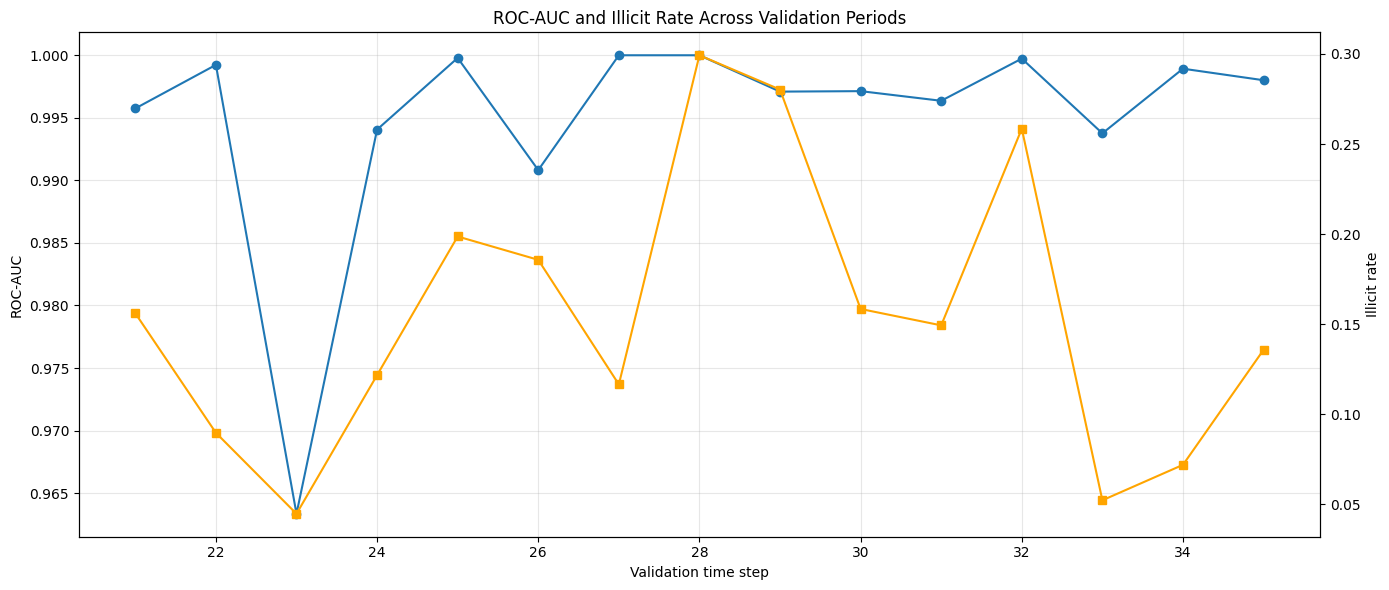

In [38]:
plot_data = best_window_with_prevalence.sort_values(
    "validation_step"
)

fig, ax1 = plt.subplots(figsize=(14, 6))

ax1.plot(
    plot_data["validation_step"],
    plot_data["roc_auc"],
    marker="o",
    label="ROC-AUC",
)

ax1.set_xlabel("Validation time step")
ax1.set_ylabel("ROC-AUC")
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()

ax2.plot(
    plot_data["validation_step"],
    plot_data["illicit_rate"],
    color="orange",
    marker="s",
    label="Illicit rate",
)

ax2.set_ylabel("Illicit rate")

plt.title(
    "ROC-AUC and Illicit Rate Across Validation Periods"
)

fig.tight_layout()
plt.show()

Lookingat at the chart, the ROC-AUC overlaps with the Illicit Rate at time_step 23, 28, 29

In [40]:
best_window_with_prevalence[
    best_window_with_prevalence["validation_step"].isin([23, 28, 29])
][
    [
        "validation_step",
        "roc_auc",
        "illicit_rate",
        "n_validation",
        "positive_validation",
    ]
]

,validation_step,roc_auc,illicit_rate,n_validation,positive_validation
2,23,0.963346,0.044650,1187,53
7,28,1.000000,0.299296,284,85
8,29,0.997094,0.280239,1174,329


In [39]:
selected_summary = pd.Series({
    "strategy": "expanding",
    "window_size": 20,
    "recency_decay": 0.03,

    "mean_roc_auc": best_window_results["roc_auc"].mean(),
    "median_roc_auc": best_window_results["roc_auc"].median(),
    "std_roc_auc": best_window_results["roc_auc"].std(),
    "worst_roc_auc": best_window_results["roc_auc"].min(),
    "latest_5_roc_auc": best_window_results.tail(5)["roc_auc"].mean(),

    # Secondary diagnostic
    "mean_pr_auc": best_window_results["pr_auc"].mean(),
})

display(selected_summary)

strategy            expanding
window_size                20
recency_decay            0.03
mean_roc_auc         0.994933
median_roc_auc       0.997131
std_roc_auc          0.009145
worst_roc_auc        0.963346
latest_5_roc_auc     0.997356
mean_pr_auc          0.973035
dtype: object